In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
def f(x):
  return 3*x**2 - 4*x +5

In [ ]:
f(3.0)

20.0

In [ ]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)

In [ ]:


ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

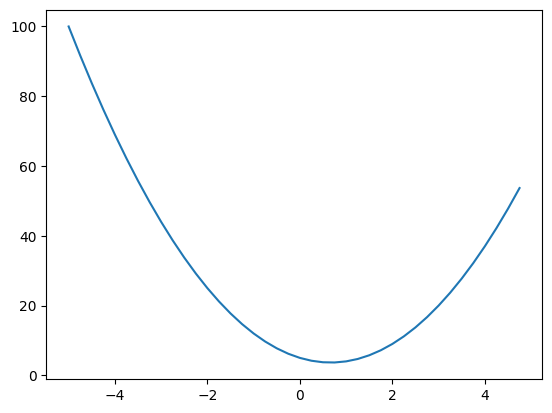

In [ ]:
plt.plot(xs, ys)

In [ ]:
class Value:
  def __init__(self, data, _children=(), _op='', label='', _grad = 0.0):
    self.data = data
    self._prev = set(_children)
    self._op = _op
    self.label = label
    self._grad = 0.0
    self._backward = lambda: None

  def __repr__(self):
    return f"Value(data={self.data})"

  def __add__(self, other):
    other = other if isinstance(other, Value)  else Value(other)
    out = Value(self.data + other.data, (self, other), '+', )

    def _backward():
      self._grad +=1.0 * out._grad
      other._grad += 1.0 * out._grad
    out._backward = _backward
    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value)  else Value(other)
    out = Value(self.data * other.data, (self, other), '*')
    def _backward():
      self._grad += other.data * out._grad
      other._grad += self.data * out._grad
    out._backward = _backward
    return out
  def __neg__(self):
    return self * -1

  def __sub__(self, other):
    return self + (-other)

  def __radd__(self, other):
    return self + other

  def __rmul__(self, other):
    return self * other

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')

    def _backward():
      self._grad += (1 - t**2) * out._grad
    out._backward = _backward
    return out

  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self,), 'exp')

    def _backward():
      self._grad += math.exp(x) * out._grad
    out._backward = _backward
    return out


  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only support int and float powers for now"
    out = Value(self.data**other, (self, ), f'**{other}')

    def _backward():
      self._grad += other * (self.data**(other-1)) * out._grad
    out._backward = _backward
    return out


  def __truediv__(self, other):
    return self * other**-1

  def backward(self):
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    self._grad = 1.0

    for node in reversed(topo):
      node._backward()


In [ ]:
a = Value(2.0)
b = Value(4.0)
a / b
a-b

Value(data=-2.0)

In [ ]:


from graphviz import Digraph

def trace(root):
  # Builds a set of nodes and edges in a graph
  nodes, edges = set(), set()

  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  nodes, edges = trace(root)

  for n in nodes:
    uid = str(id(n))
    # for every value in the graph create a rectangular ('record') node for it
    dot.node(name=uid, label="{ %s | data %.4f | _grad %.3f }" % (n.label, n.data, n._grad), shape='record')

    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name=uid + n._op, label=n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [ ]:
def lol():
  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  c = Value(10.0, label='c')
  e = a*b
  e.label = 'e'
  d = e + c
  d.label = 'd'
  f = Value(-2.0, label='f')
  L = d * f
  L.label = 'L'
  L1 = L.data

  #deriving
  h = 0.001

  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  c = Value(10.0 , label='c')
  e = a*b
  e.label = 'e'
  d = e + c
  d.label = 'd'
  f = Value(-2.0, label='f')
  L = d * f
  L.label = 'L'

  L2 = L.data

  print((L2-L1)/h)

In [ ]:
#Inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

#weignts
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias
b = Value(6.7, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1w1 + x2w2'

n = x1w1x2w2 + b; n.label = 'n'


In [ ]:

o =  n.tanh()
o.label = 'o'
o.backward()


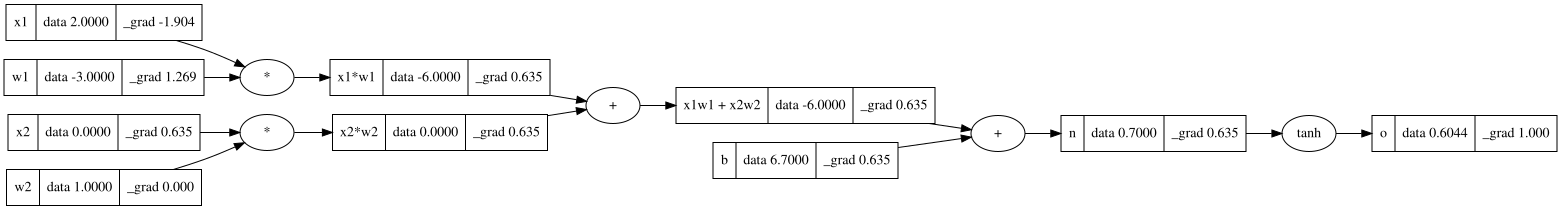

In [ ]:

draw_dot(o)

In [ ]:
#Inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

#weignts
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias
b = Value(6.7, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1w1 + x2w2'

n = x1w1x2w2 + b; n.label = 'n'

e = (2*n).exp()
o= ( e - 1) / (e + 1)


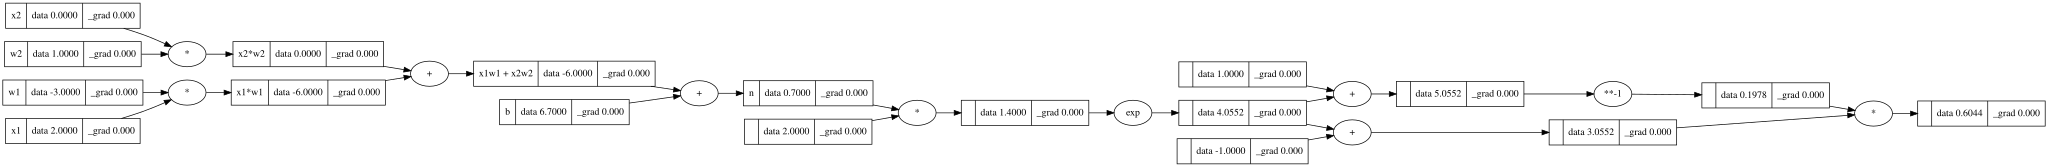

In [ ]:
draw_dot(o)

In [ ]:
o.backward()

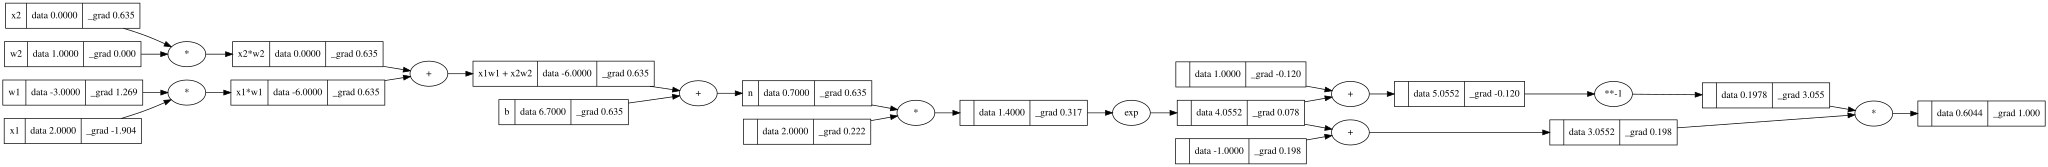

In [ ]:
draw_dot(o)

In [ ]:

import torch
x =  torch.Tensor([2.0]).double()
x1 =  torch.Tensor([0.0]).double()
w =  torch.Tensor([-3.0]).double()
w1 =  torch.Tensor([1.0]).double()
b = torch.Tensor([6.8813735870195432]).double()


x.requires_grad = True
x1.requires_grad = True
w.requires_grad = True
w1.requires_grad = True


n = x*w + x1*w1 + b
o = torch.tanh(n)

In [ ]:
import random
class Neuron:

  def __init__(self,nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))

  def __call__(self,x):
      # w*x + b

      act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
      out = act.tanh()
      return out
  def parameters(self):
    return self.w + [b]

class Layer:
  def __init__(self, nin, nout):
      self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self,x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [p for n in self.neurons for p in n.parameters()]

class MLP:
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for l in self.layers for p in l.parameters()]

In [ ]:
x = [2.0,3.0,-1.0]
n = MLP(3,[4,4,1])
n(x)

Value(data=-0.7805167559411924)

In [ ]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, 1.0, 1.0],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0]

In [ ]:
n.parameters()

[Value(data=0.7967821164557731),
 Value(data=-0.7247678186221187),
 Value(data=0.8350375779261514),
 tensor([6.8814], dtype=torch.float64),
 Value(data=-0.4989181471153281),
 Value(data=0.11506899870348541),
 Value(data=-0.5494734595695556),
 tensor([6.8814], dtype=torch.float64),
 Value(data=-0.7941864680647897),
 Value(data=0.6338287965510054),
 Value(data=0.2801585130747557),
 tensor([6.8814], dtype=torch.float64),
 Value(data=-0.3700909433740407),
 Value(data=-0.07477099651186281),
 Value(data=0.8975354192734877),
 tensor([6.8814], dtype=torch.float64),
 Value(data=-0.9235032783259378),
 Value(data=0.799882517054253),
 Value(data=0.9689031528953396),
 Value(data=-0.46967259622809654),
 tensor([6.8814], dtype=torch.float64),
 Value(data=0.1898237768678328),
 Value(data=-0.31159001167809564),
 Value(data=0.20020249259836653),
 Value(data=-0.689053152378688),
 tensor([6.8814], dtype=torch.float64),
 Value(data=0.05073130996942865),
 Value(data=0.05392829025911472),
 Value(data=0.25336

In [ ]:

#Training Loop
for i in range(20):
  # forward pass
  ypred = [n(x) for x in xs]
  loss = sum((ytg - yout)**2 for yout, ytg in zip(ys, ypred))

  # backward pass
  for p in n.parameters():
    p._grad = 0.0
  loss.backward()

  # update
  for p in n.parameters():
    p.data += -0.01 * p._grad

  print(i, loss.data)

TypeError: assigned grad expected to be a Tensor or None but got grad of type float

In [ ]:
ypred